# Notebook 5 -- Analysis of the Final Model

**Purpose:** a closer look at the final XGBoost model than a single accuracy number: which scores it is tested on, where it errs, and how confident it is.

Two evaluations are compared throughout:
- **Cross-validation (2017-2019):** out-of-fold predictions from 5-fold `GroupKFold` grouped by fire, using the same model settings as Notebook 3. Every drop is scored by a model that never saw its fire.
- **Validation (2020-2021):** `models/model_final_xgboost.pkl` scored on the student-labeled drops from Notebook 4.

In [1]:
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
RAW, INTERIM, FEATS, MODELS, OUT = (ROOT / p for p in
    ["data/raw", "data/interim", "data/features", "models", "outputs"])
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

In [2]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, log_loss, brier_score_loss,
                             confusion_matrix, roc_curve)

BLUE, ORANGE = "#2a78d6", "#eb6834"      # CV (2017-2019) / validation (2020-2021)
AQUA, VIOLET = "#1baf7a", "#6250d6"      # protected / origin
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.dpi": 110})

## 1. Build both datasets

Same preprocessing as Notebooks 3 and 4: clean pairs only, three mean-DOB columns filled with 0, then the paired-difference features.

In [3]:
KEYS = ["event_id", "buff_id", "drop_id"]
features = joblib.load(MODELS / "model_features_xgboost.pkl")

def load(folder, suffix):
    df = pd.read_csv(folder / f"training_features_dob{suffix}.csv")
    for name in ["split", "dist", "expanded"]:
        df = df.merge(pd.read_csv(folder / f"training_features_{name}{suffix}.csv"), on=KEYS, how="left")
    return df[df["pt"].isin([0, 1])]

def preprocess(df):
    sizes = df.groupby("drop_id").size()
    df = df[df["drop_id"].isin(sizes[sizes == 2].index)].copy()
    for col in ["mean_dob", "median_dob", "split_mean_dob"]:
        df[col] = df[col].fillna(0)
    pair_diff = {"unburned_pair_diff": "unburned_pixels", "early_pair_diff": "early_pixels",
                 "burned_pair_diff": "burned_pixels",
                 "split_unburned_pair_diff": "split_unburned_pixels", "split_early_pair_diff": "split_early_pixels",
                 "split_burned_pair_diff": "split_burned_pixels",
                 "exp_burned_pair_diff": "exp_burned_pixels", "exp_unburned_pair_diff": "exp_unburned_pixels",
                 "exp_early_pair_diff": "exp_early_pixels", "dist_pair_diff": "dist_to_unburned"}
    for new, col in pair_diff.items():
        df[new] = df[col] - df.groupby("drop_id")[col].transform("mean")
    return df.dropna(subset=features + ["pt"]).reset_index(drop=True)

train = preprocess(load(FEATS / "train", ""))
val = preprocess(load(FEATS / "val_2021", "_2021"))
print(f"2017-2019: {len(train)} rows, {train['drop_id'].nunique()} drops, {train['event_id'].nunique()} fires")
print(f"2020-2021: {len(val)} rows, {val['drop_id'].nunique()} drops, {val['event_id'].nunique()} fires")

2017-2019: 20022 rows, 10236 drops, 420 fires
2020-2021: 23854 rows, 12145 drops, 340 fires


## 2. Predictions

- **2017-2019:** out-of-fold probabilities (each fold's model never saw the test fires).
- **2020-2021:** the saved final model.

`proba` is the model's probability that the side is protected; `predicted` thresholds it at 0.5.

In [4]:
params = dict(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42,
              eval_metric="logloss", verbosity=0)

train["proba"] = np.nan
for tr, te in GroupKFold(n_splits=5).split(train, train["pt"], train["event_id"]):
    m = xgb.XGBClassifier(**params).fit(train.loc[tr, features], train.loc[tr, "pt"])
    train.loc[te, "proba"] = m.predict_proba(train.loc[te, features])[:, 1]

model = joblib.load(MODELS / "model_final_xgboost.pkl")
val["proba"] = model.predict_proba(val[features])[:, 1]

for df in (train, val):
    df["predicted"] = (df["proba"] >= 0.5).astype(int)
sets = {"CV 2017-2019": (train, BLUE), "Validation 2020-2021": (val, ORANGE)}

## 3. Which scores, and what each one tells you

| Score | Question it answers |
|---|---|
| **Accuracy** | What share of sides is labeled correctly? Meaningful here because the classes are about 50/50. |
| **Precision** | When the model says "protected", how often is it right? |
| **Recall** | Of the truly protected sides, how many does it find? |
| **F1** | The harmonic mean of precision and recall. |
| **ROC AUC** | How well do the probabilities rank protected above origin, regardless of threshold? (0.5 = chance, 1 = perfect.) |
| **MCC** | One correlation-style score that uses all four cells of the confusion matrix (0 = chance, 1 = perfect). |
| **Log loss / Brier** | Are the *probabilities* good, not just the labels? Lower is better. Confident wrong answers are penalized heavily. |

In [5]:
rows = {}
for name, (df, _) in sets.items():
    y, p, yhat = df["pt"], df["proba"], df["predicted"]
    rows[name] = {"Accuracy": accuracy_score(y, yhat), "Precision": precision_score(y, yhat),
                  "Recall": recall_score(y, yhat), "F1": f1_score(y, yhat),
                  "ROC AUC": roc_auc_score(y, p), "MCC": matthews_corrcoef(y, yhat),
                  "Log loss": log_loss(y, p), "Brier": brier_score_loss(y, p)}
pd.DataFrame(rows).round(3)

,CV 2017-2019,Validation 2020-2021
Accuracy,0.915,0.896
Precision,0.914,0.900
Recall,0.912,0.887
F1,0.913,0.893
ROC AUC,0.972,0.956
MCC,0.830,0.792
Log loss,0.217,0.269
Brier,0.063,0.080


## 4. Confusion matrices

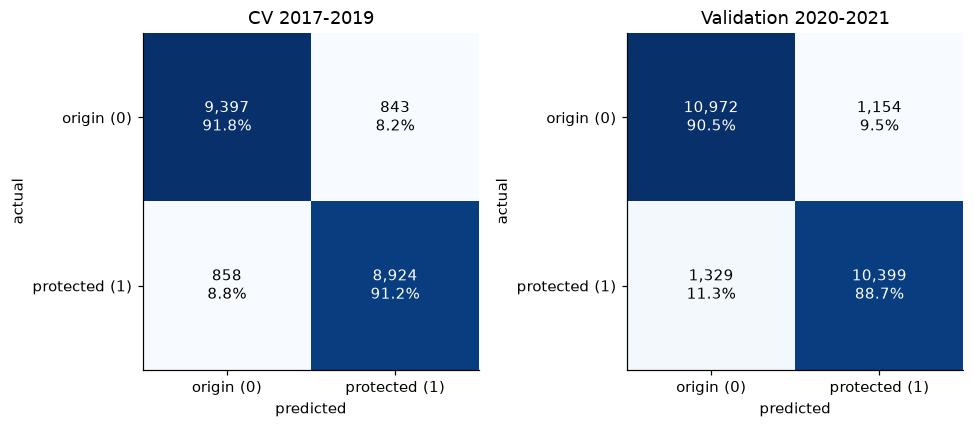

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, (df, color)) in zip(axes, sets.items()):
    cm = confusion_matrix(df["pt"], df["predicted"])
    ax.imshow(cm, cmap="Blues")
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{cm[i, j] / cm[i].sum():.1%}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["origin (0)", "protected (1)"]); ax.set_yticks([0, 1], ["origin (0)", "protected (1)"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(name)
plt.tight_layout()
plt.savefig(FIGS / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. ROC curve and probability calibration

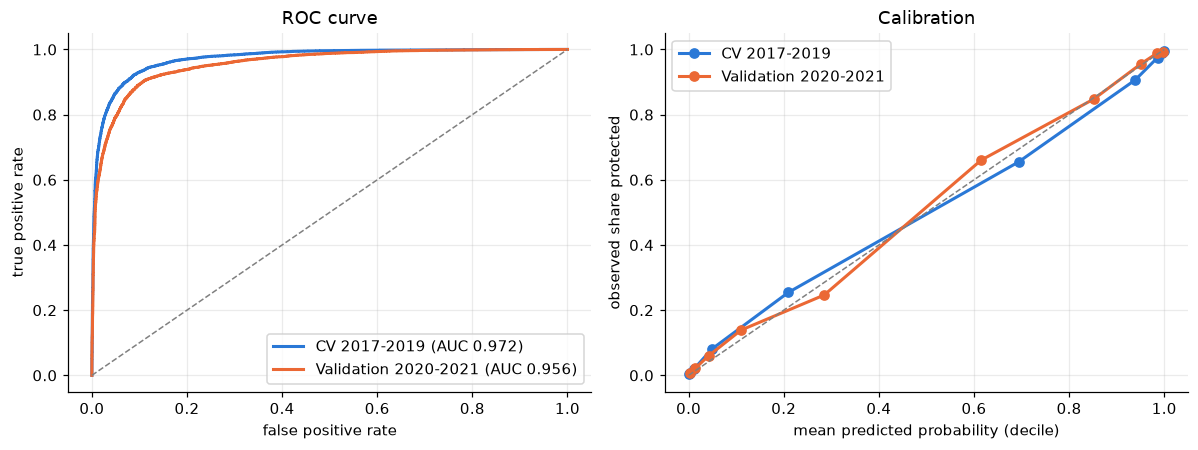

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for name, (df, color) in sets.items():
    fpr, tpr, _ = roc_curve(df["pt"], df["proba"])
    ax1.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {roc_auc_score(df['pt'], df['proba']):.3f})")
    # calibration: mean predicted probability vs observed protected rate, by probability decile
    b = pd.qcut(df["proba"], 10, duplicates="drop")
    g = df.groupby(b, observed=True).agg(pred=("proba", "mean"), obs=("pt", "mean"))
    ax2.plot(g["pred"], g["obs"], "o-", color=color, lw=2, ms=6, label=name)
ax1.plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
ax1.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve"); ax1.legend(loc="lower right")
ax2.plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
ax2.set(xlabel="mean predicted probability (decile)", ylabel="observed share protected", title="Calibration"); ax2.legend()
plt.tight_layout()
plt.savefig(FIGS / "roc_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. How confident is the model?

Predicted probability by true class. Wrong answers sitting near 0.5 are uncertain cases; wrong answers near 0 or 1 are confident mistakes (the first place to look for mislabeled data).

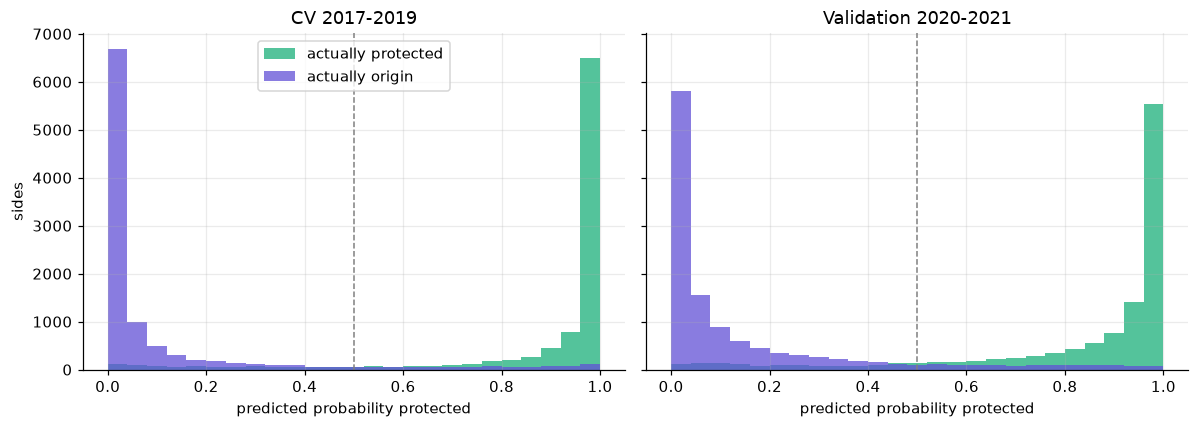

CV 2017-2019: 1701 wrong sides; 28.3% of them with probability >0.9 or <0.1 (confident mistakes)
Validation 2020-2021: 2483 wrong sides; 21.5% of them with probability >0.9 or <0.1 (confident mistakes)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
bins = np.linspace(0, 1, 26)
for ax, (name, (df, _)) in zip(axes, sets.items()):
    ax.hist(df.loc[df["pt"] == 1, "proba"], bins, color=AQUA, alpha=.75, label="actually protected")
    ax.hist(df.loc[df["pt"] == 0, "proba"], bins, color=VIOLET, alpha=.75, label="actually origin")
    ax.axvline(.5, color="gray", ls="--", lw=1)
    ax.set(xlabel="predicted probability protected", title=name)
axes[0].set_ylabel("sides"); axes[0].legend(loc="upper center")
plt.tight_layout()
plt.savefig(FIGS / "confidence_hist.png", dpi=150, bbox_inches="tight")
plt.show()

for name, (df, _) in sets.items():
    wrong = df[df["pt"] != df["predicted"]]
    conf = (wrong["proba"].sub(.5).abs() > .4).mean()
    print(f"{name}: {len(wrong)} wrong sides; {conf:.1%} of them with probability >0.9 or <0.1 (confident mistakes)")

## 7. Drop-level view

Each drop has one protected and one origin side, so the two sides' predictions can be combined: call the side with the higher probability protected. This enforces exactly one protected side per drop.

In [9]:
def drop_level(df):
    out = []
    for _, g in df.groupby("drop_id"):
        pred = (g["proba"] == g["proba"].max()).astype(int)
        one_protected = g["pt"].sum() == 1
        out.append({"one_protected": one_protected,
                    "threshold_consistent": g["predicted"].sum() == 1,
                    "pair_correct": one_protected and (pred == g["pt"]).all()})
    return pd.DataFrame(out)

summary = {}
for name, (df, _) in sets.items():
    d = drop_level(df)
    summary[name] = {
        "Drops": f"{len(d):,}",
        "Drops labeled with exactly one protected side": f"{d['one_protected'].mean():.1%}",
        "Threshold at 0.5 gives exactly one protected side": f"{d['threshold_consistent'].mean():.1%}",
        "Drop correct when the higher-probability side is protected": f"{d['pair_correct'].sum() / d['one_protected'].sum():.1%}"}
pd.DataFrame(summary)

,CV 2017-2019,Validation 2020-2021
Drops,"10,236","12,145"
Drops labeled with exactly one protected side,95.6%,96.4%
Threshold at 0.5 gives exactly one protected side,92.6%,89.9%
Drop correct when the higher-probability side is protected,91.8%,90.4%


## 8. Per-fire accuracy and feature importance

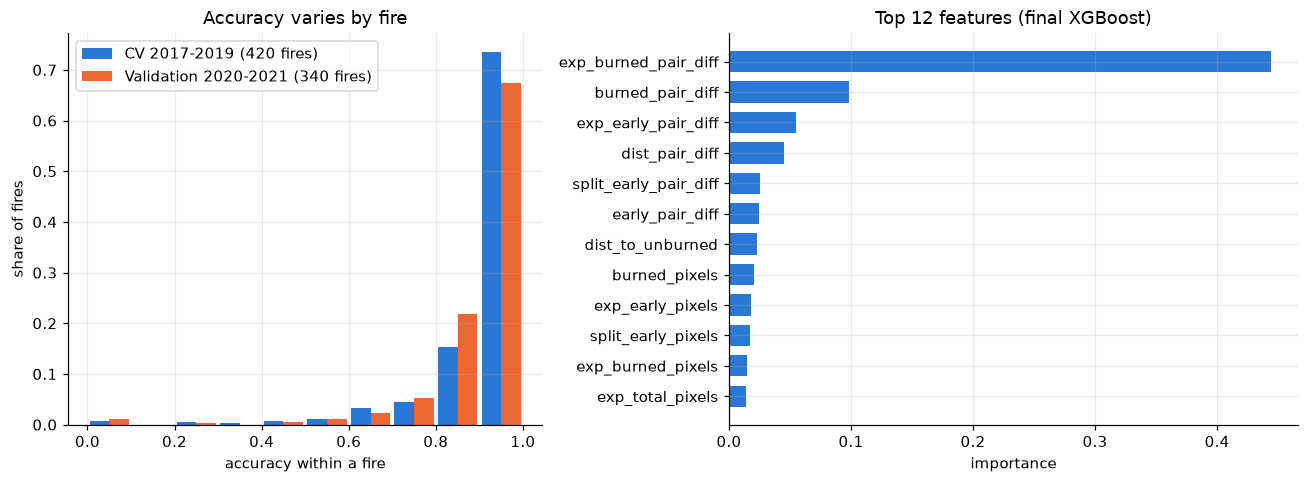

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})

edges = np.linspace(0, 1, 11)
centers = (edges[:-1] + edges[1:]) / 2
for k, (name, (df, color)) in enumerate(sets.items()):
    per_fire = (df["pt"] == df["predicted"]).groupby(df["event_id"]).mean()
    share = np.histogram(per_fire, edges)[0] / len(per_fire)
    ax1.bar(centers + (k - .5) * .045, share, width=.045, color=color, label=f"{name} ({len(per_fire)} fires)")
ax1.set(xlabel="accuracy within a fire", ylabel="share of fires", title="Accuracy varies by fire"); ax1.legend(loc="upper left")

imp = pd.Series(model.feature_importances_, index=features).sort_values().tail(12)
ax2.barh(imp.index, imp.values, color=BLUE, height=.7)
ax2.set(xlabel="importance", title="Top 12 features (final XGBoost)")
plt.tight_layout()
plt.savefig(FIGS / "fire_accuracy_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Summary

- **Scores:** accuracy 91.5% in cross-validation and 89.6% on 2020-2021. Precision and recall are balanced in both (about 0.91 in CV, 0.90 and 0.89 in validation), ROC AUC is 0.97 and 0.96, and MCC is 0.83 and 0.79.
- **Generalization:** the drop from CV to validation is about 2 points of accuracy and 0.05 of log loss. The validation fires are different years and were labeled by different people, so the model transfers, with some loss.
- **Errors:** the errors are split about evenly between the two classes. On 2020-2021 the model misses slightly more protected sides (11.3%) than it mislabels origin sides (9.5%).
- **Probabilities:** the calibration curves sit close to the diagonal, so the predicted probability is a usable confidence. Most mistakes are not confident ones: only 28% (CV) and 22% (validation) of the wrong sides have a probability above 0.9 or below 0.1, and those are the first cases to check for mislabeled data.
- **Pairing:** thresholding each side independently gives exactly one protected side in 93% (CV) and 90% (validation) of drops. Picking the higher-probability side as protected makes this consistent by construction.
- **Features:** the expanded-polygon paired difference (`exp_burned_pair_diff`) carries about 44% of the final model's importance, followed by the local burned paired difference.
- **Fires:** most fires are predicted at 90% or better, with a tail of fires that score much lower.